In [ ]:
import pandas as pd
from utils import merge_csv_files_in_directory, standardize_labels
from IPython.display import display, HTML

df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)
df.drop("file_name",inplace = True,axis=1)
df.drop("full_repo_name",inplace = True,axis=1)

#df.drop("content_before",inplace = True,axis=1)
#df.drop("content_after",inplace = True,axis=1)

df.drop("patch",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)

# ### Limit df size for testing purposes ###
# # Sample 10 rows of each label type
# label_enh = df[df['labels'] == 'enhancement']
# label_bug = df[df['labels'] == 'bug']
# sampled_enh = label_enh.sample(n=20, random_state=1)
# sampled_bug = label_bug.sample(n=20, random_state=1)
# df = pd.concat([sampled_enh, sampled_bug])

# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

# Display DataFrame with a scrollable table
#display(HTML(df.to_html(max_rows=None, max_cols=None)))

# Count the occurrences of each unique value in the 'lables' column
label_counts = df['labels'].value_counts()
print(label_counts)

df

Files have been merged and saved as merged.csv


In [ ]:
def filter_invalid_data(df):
    # Keep only rows where both 'content_before' and 'content_after' are valid non-empty strings
    valid_df = df[df['content_before'].apply(lambda x: isinstance(x, str) and x.strip()) & 
                  df['content_after'].apply(lambda x: isinstance(x, str) and x.strip())]
    return valid_df

df = filter_invalid_data(df)

df

In [2]:
from transformers import AutoTokenizer, AutoModel
import torch

tokenizer = AutoTokenizer.from_pretrained("microsoft/codebert-base")
model = AutoModel.from_pretrained("microsoft/codebert-base")

/opt/miniconda3/envs/code1001/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [3]:
import os

# Directory to save embeddings
save_dir = "embeddings"
os.makedirs(save_dir, exist_ok=True)

In [4]:

# Tokenizing using subtracting full code before and after embeddings

def generate_and_save_embeddings_batch(contents_before, contents_after, indices):

    # Tokenize the before and after code snippets
    tokens_before = tokenizer(list(contents_before), truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    tokens_after = tokenizer(list(contents_after), truncation=True, padding='max_length', max_length=512, return_tensors='pt')

    # Get the embeddings for both tokenized sequences
    with torch.no_grad():
        embeddings_before = model(**tokens_before).last_hidden_state
        embeddings_after = model(**tokens_after).last_hidden_state
    
    # Subtract the embeddings
    subtracted_embeddings = embeddings_after - embeddings_before
    
    # Average the subtracted embeddings across the token dimension
    subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
    for i, idx in enumerate(indices):
        save_path = os.path.join(save_dir, f"embedding_{idx.item()}.pt")
        torch.save(subtracted_embeddings[i], save_path)
    

In [5]:
from torch.utils.data import DataLoader, Dataset

# Custom Dataset Class to handle the dataframe
class CodeDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        content_before = row['content_before']
        content_after = row['content_after']
        return content_before, content_after, idx

In [6]:

# Creating a DataLoader
def create_dataloader(dataframe, batch_size=32, shuffle=False):
    dataset = CodeDataset(dataframe)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

batch_size = 128
dataloader = create_dataloader(df, batch_size=batch_size)

for batch in dataloader:
    contents_before, contents_after, indices = batch
    generate_and_save_embeddings_batch(contents_before, contents_after, indices)


TypeError: TextEncodeInput must be Union[TextInputSequence, Tuple[InputSequence, InputSequence]]

In [1]:
# Alternate starting node, if embeddings will be loaded

from utils import load_embeddings_from_directory, merge_csv_files_in_directory, standardize_labels


df = merge_csv_files_in_directory()

#remove duplicates
df = df.drop_duplicates(keep='first')

df.drop("pr_title",inplace = True,axis=1)
df.drop("class_names",inplace = True,axis=1)
df.drop("commit_sha",inplace = True,axis=1)
df.drop("commit_message",inplace = True,axis=1)
df.drop("file_path",inplace = True,axis=1)
df.drop("additions",inplace = True,axis=1)
df.drop("deletions",inplace = True,axis=1)
df.drop("file_name",inplace = True,axis=1)
df.drop("full_repo_name",inplace = True,axis=1)

df.drop("patch",inplace = True,axis=1)

df.drop("created_at",inplace = True,axis=1)
df.drop("closed_at",inplace = True,axis=1)
df.drop("status",inplace = True,axis=1)

# Standardize labels
labels = ['bug', 'enhancement', 'performance', 'refactor', 'clean']
df = standardize_labels(df, labels)
resulting_label_count = df['labels'].nunique()

# Load embeddings from embeddings folder
all_embeddings = load_embeddings_from_directory('embeddings')

# Convert the embeddings to a DataFrame or add them to the original DataFrame
df['tokens'] = list(all_embeddings)

df

Files have been merged and saved as merged.csv


,labels,content_before,content_after,tokens
0,bug,// Licensed to the Apache Software Foundation ...,// Licensed to the Apache Software Foundation ...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
1,bug,// Licensed to the Apache Software Foundation ...,// Licensed to the Apache Software Foundation ...,"[tensor(-0.0053), tensor(0.0043), tensor(0.004..."
2,bug,// Licensed to the Apache Software Foundation ...,// Licensed to the Apache Software Foundation ...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
3,bug,// Licensed to the Apache Software Foundation ...,// Licensed to the Apache Software Foundation ...,"[tensor(0.0022), tensor(-0.0015), tensor(-0.00..."
4,bug,// Licensed to the Apache Software Foundation ...,// Licensed to the Apache Software Foundation ...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
...,...,...,...,...
18637,enhancement,/*\n * Licensed to the Apache Software Founda...,/*\n * Licensed to the Apache Software Founda...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
18638,enhancement,/*\n * Licensed to the Apache Software Founda...,/*\n * Licensed to the Apache Software Founda...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
18639,enhancement,/*\n * Licensed to the Apache Software Founda...,/*\n * Licensed to the Apache Software Founda...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."
18640,enhancement,/*\n * Licensed to the Apache Software Founda...,/*\n * Licensed to the Apache Software Founda...,"[tensor(0.), tensor(0.), tensor(0.), tensor(0...."


In [ ]:
def filter_invalid_data(df):
    # Keep only rows where both 'content_before' and 'content_after' are valid non-empty strings
    valid_df = df[df['content_before'].apply(lambda x: isinstance(x, str) and x.strip()) & 
                  df['content_after'].apply(lambda x: isinstance(x, str) and x.strip())]
    return valid_df

df = filter_invalid_data(df)

df

In [2]:
# # Tokenizing using patch
# import torch
# from utils import extract_code_from_patch

# def tokenize_code(row):

#     patch_before, patch_after = extract_code_from_patch(row['patch'])
    
#     # Tokenize the before and after code snippets
#     tokens_before = tokenizer(patch_before, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
#     tokens_after = tokenizer(patch_after, truncation=True, padding='max_length', max_length=512, return_tensors='pt')
    
#     # Get the embeddings for both tokenized sequences
#     with torch.no_grad():
#         embeddings_before = model(**tokens_before).last_hidden_state
#         embeddings_after = model(**tokens_after).last_hidden_state
    
#     # Ensure the two tensors are of the same shape before subtracting
#     assert embeddings_before.shape == embeddings_after.shape, "Shape mismatch between before and after embeddings"
    
#     # Subtract the embeddings
#     subtracted_embeddings = embeddings_after - embeddings_before
    
#     # Average the subtracted embeddings across the token dimension
#     # to get a single vector representation for each input. (2D tensor instead of 3D)
#     subtracted_embeddings = subtracted_embeddings.mean(dim=1)
    
#     return subtracted_embeddings

# df['tokens'] = df.apply(tokenize_code, axis=1)
# df

In [3]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression # Classification
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
import pandas as pd
import torch

# One-hot encoding ile labels sütununu dönüştürme
df_encoded = pd.get_dummies(df, columns=['labels'])

# Özellikler ve etiketler
X = torch.stack(tuple(df['tokens'].values))
y = df_encoded.drop(columns=['content_before', 'content_after', 'tokens'])
y = y.astype(int) # convert it 0,1     instead of true, false 

# Eğitim ve test setlerine bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #random_state: 0,3074,42

X_test

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0263,  0.0312,  0.0080,  ...,  0.0261, -0.0069,  0.0147],
        ...,
        [-0.0030,  0.0059,  0.0005,  ...,  0.0066, -0.0025,  0.0013],
        [-0.0099, -0.0701,  0.0284,  ...,  0.0053, -0.0103, -0.0002],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]])

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Flattening the 3D tensor to 2D
X_train = X_train.view(X_train.size(0), -1) 
X_test = X_test.view(X_test.size(0), -1)  

# # Scaling X values so that the mean is 0 and the st.dev. is 1
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# # Converting inputs back to tensors
# X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
# X_test = torch.tensor(X_test_scaled, dtype=torch.float32)

# Turning y into tensors
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_test = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

print(y_train)
print(X_train)

tensor([[1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        ...,
        [1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 1., 0., 0., 0.]])
tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0119,  0.0136, -0.0244,  ...,  0.0700,  0.0028, -0.0047],
        ...,
        [-0.0043, -0.0039, -0.0020,  ..., -0.0078,  0.0044, -0.0049],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0105,  0.0178,  0.0059,  ...,  0.0115,  0.0063, -0.0077]])


In [48]:
# Create DataLoader
batch_size = 128
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

In [49]:
import torch.nn as nn

# Define the ANN model
class CodeDiffNN(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout_rate=0.1):
        super(CodeDiffNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_sizes[0])
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout_rate)  # Dropout layer after first hidden layer
        
        self.fc2 = nn.Linear(hidden_sizes[0], hidden_sizes[1])
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout_rate)  # Dropout layer after second hidden layer
        
        self.fc3 = nn.Linear(hidden_sizes[1], hidden_sizes[2])
        self.relu3 = nn.ReLU()
        
        self.fc4 = nn.Linear(hidden_sizes[2], output_size)
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.dropout1(x) 
        
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.dropout2(x) 
        
        x = self.fc3(x)
        x = self.relu3(x) 
        
        x = self.fc4(x)
        return x


In [50]:
# Define model parameters
print(X_train.shape)
input_size = X_train.shape[1]
hidden_sizes = [512, 256, 128]
output_size = resulting_label_count

model = CodeDiffNN(input_size, hidden_sizes, output_size)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

torch.Size([14528, 768])


In [51]:

# Function to calculate accuracy
def calculate_accuracy(outputs, labels):
    
    _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
    labels_1d = torch.argmax(labels, dim=1) # turn into 1D tensor
    correct = (predicted == labels_1d).sum().item()
    accuracy = correct / labels.size(0)  # Accuracy = number of correct predictions / total number of samples
    return accuracy

# Train the model
num_epochs = 500
for epoch in range(num_epochs):
    model.train()  # Set the model to training mode
    running_loss = 0.0
    running_accuracy = 0.0
    
    for batch_X, batch_y in train_loader:
        # Zero the parameter gradients
        optimizer.zero_grad()
    
        # Forward pass
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
    
        # Backward pass and optimization
        loss.backward()
        optimizer.step()
        
        # Calculate accuracy
        accuracy = calculate_accuracy(outputs, batch_y)
        
        # Update running loss and accuracy
        running_loss += loss.item()
        running_accuracy += accuracy
    
    # Print average loss and accuracy for the epoch
    avg_loss = running_loss / len(train_loader)
    avg_accuracy = running_accuracy / len(train_loader)
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Accuracy: {avg_accuracy:.4f}')



Epoch [1/500], Loss: 1.5594, Accuracy: 0.3044
Epoch [2/500], Loss: 1.4931, Accuracy: 0.3812
Epoch [3/500], Loss: 1.4915, Accuracy: 0.3811
Epoch [4/500], Loss: 1.4913, Accuracy: 0.3806
Epoch [5/500], Loss: 1.4910, Accuracy: 0.3803
Epoch [6/500], Loss: 1.4903, Accuracy: 0.3808
Epoch [7/500], Loss: 1.4900, Accuracy: 0.3804
Epoch [8/500], Loss: 1.4889, Accuracy: 0.3806
Epoch [9/500], Loss: 1.4880, Accuracy: 0.3813
Epoch [10/500], Loss: 1.4879, Accuracy: 0.3810
Epoch [11/500], Loss: 1.4862, Accuracy: 0.3812
Epoch [12/500], Loss: 1.4861, Accuracy: 0.3811
Epoch [13/500], Loss: 1.4857, Accuracy: 0.3813
Epoch [14/500], Loss: 1.4834, Accuracy: 0.3818
Epoch [15/500], Loss: 1.4822, Accuracy: 0.3827
Epoch [16/500], Loss: 1.4802, Accuracy: 0.3827
Epoch [17/500], Loss: 1.4799, Accuracy: 0.3833
Epoch [18/500], Loss: 1.4783, Accuracy: 0.3823
Epoch [19/500], Loss: 1.4761, Accuracy: 0.3836
Epoch [20/500], Loss: 1.4731, Accuracy: 0.3853
Epoch [21/500], Loss: 1.4717, Accuracy: 0.3847
Epoch [22/500], Loss: 

Epoch [174/500], Loss: 1.0670, Accuracy: 0.5720
Epoch [175/500], Loss: 1.0627, Accuracy: 0.5745
Epoch [176/500], Loss: 1.0640, Accuracy: 0.5721
Epoch [177/500], Loss: 1.0676, Accuracy: 0.5740
Epoch [178/500], Loss: 1.0622, Accuracy: 0.5738
Epoch [179/500], Loss: 1.0585, Accuracy: 0.5763
Epoch [180/500], Loss: 1.0593, Accuracy: 0.5766
Epoch [181/500], Loss: 1.0609, Accuracy: 0.5772
Epoch [182/500], Loss: 1.0560, Accuracy: 0.5761
Epoch [183/500], Loss: 1.0533, Accuracy: 0.5789
Epoch [184/500], Loss: 1.0553, Accuracy: 0.5770
Epoch [185/500], Loss: 1.0556, Accuracy: 0.5761
Epoch [186/500], Loss: 1.0584, Accuracy: 0.5752
Epoch [187/500], Loss: 1.0514, Accuracy: 0.5790
Epoch [188/500], Loss: 1.0485, Accuracy: 0.5783
Epoch [189/500], Loss: 1.0523, Accuracy: 0.5780
Epoch [190/500], Loss: 1.0456, Accuracy: 0.5786
Epoch [191/500], Loss: 1.0449, Accuracy: 0.5819
Epoch [192/500], Loss: 1.0530, Accuracy: 0.5793
Epoch [193/500], Loss: 1.0414, Accuracy: 0.5807
Epoch [194/500], Loss: 1.0432, Accuracy:

Epoch [345/500], Loss: 0.9869, Accuracy: 0.5899
Epoch [346/500], Loss: 0.9880, Accuracy: 0.5905
Epoch [347/500], Loss: 0.9871, Accuracy: 0.5900
Epoch [348/500], Loss: 0.9858, Accuracy: 0.5908
Epoch [349/500], Loss: 0.9851, Accuracy: 0.5904
Epoch [350/500], Loss: 0.9852, Accuracy: 0.5907
Epoch [351/500], Loss: 0.9833, Accuracy: 0.5907
Epoch [352/500], Loss: 0.9823, Accuracy: 0.5905
Epoch [353/500], Loss: 0.9835, Accuracy: 0.5933
Epoch [354/500], Loss: 0.9813, Accuracy: 0.5924
Epoch [355/500], Loss: 0.9814, Accuracy: 0.5917
Epoch [356/500], Loss: 0.9834, Accuracy: 0.5909
Epoch [357/500], Loss: 0.9840, Accuracy: 0.5903
Epoch [358/500], Loss: 0.9827, Accuracy: 0.5910
Epoch [359/500], Loss: 0.9875, Accuracy: 0.5903
Epoch [360/500], Loss: 0.9850, Accuracy: 0.5898
Epoch [361/500], Loss: 0.9850, Accuracy: 0.5908
Epoch [362/500], Loss: 0.9836, Accuracy: 0.5909
Epoch [363/500], Loss: 0.9835, Accuracy: 0.5887
Epoch [364/500], Loss: 0.9839, Accuracy: 0.5894
Epoch [365/500], Loss: 0.9833, Accuracy:

In [52]:
with torch.no_grad():
    model.eval()
    test_outputs = model(X_test)
    
    # Apply torch.max to get the index of the maximum value
    _, predicted_1d = torch.max(test_outputs, 1)
    
    # Calculate accuracy by comparing with y_test
    y_test_1d = torch.argmax(y_test, dim=1) # turn into 1D tensor
    accuracy = (predicted_1d == y_test_1d).float().mean()
    print(f'Accuracy: {accuracy:.4f}')
    
    print(predicted_1d)
    print(y_test_1d)

Accuracy: 0.3333
tensor([0, 0, 2,  ..., 0, 0, 0])
tensor([4, 4, 2,  ..., 1, 1, 2])


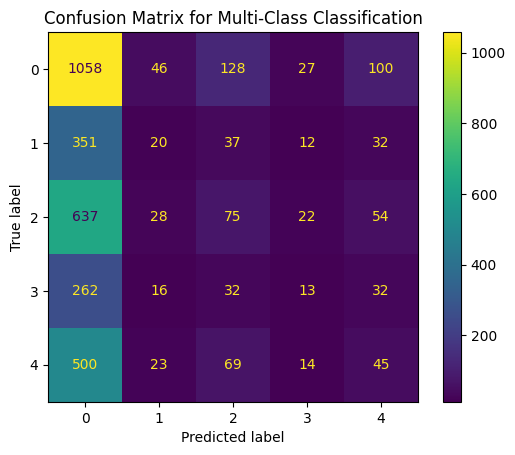

In [53]:
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt
    
    # Convert to numpy arrays
    y_test_np = y_test_1d.numpy()
    predicted_np = predicted_1d.numpy()
    
    # Compute confusion matrix
    cm = confusion_matrix(y_test_np, predicted_np)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title('Confusion Matrix for Multi-Class Classification')
    plt.show()

In [11]:
### DEPRECATED ###

In [12]:

# # Örnek tahminler
# sample_data = pd.DataFrame({
#     'file_name': ['ProtoSubject.java','BasicAnnotationProcessor.java'], #1:enhancement, 2:enhancement
#     'full_repo_name': ['google/truth','google/auto']
# })

# # Kodlama işlemleri
# sample_data['file_name_encoded'] = le_class.transform(sample_data['file_name'])
# sample_data['full_repo_name_encoded'] = le_repo.transform(sample_data['full_repo_name'])

# # Özellikleri hazırlama
# X_sample = sample_data[['file_name_encoded', 'full_repo_name_encoded']]
# X_sample = torch.tensor(X_sample.to_numpy(), dtype=torch.float32)

# with torch.no_grad():
#     model.eval()
#     test_outputs = model(X_sample)
#     predicted = torch.sigmoid(test_outputs)  # Sigmoid fonksiyonu uygulanmalı
#     print( predicted)
#     predicted = (predicted > 0.5).float()  # 0.5'ten büyük olanlar 1, diğerleri 0
#     print("after ceiling")
#     print( predicted)